# What behaviour carries the neural correlates of LD1?

LD1 relates to the Fano-factor quench and to noise correlations (`lda1_neural_summary`), and LD1 itself correlates with many behavioural measures — reaction time, engagement switching, trial-mode entropy, accuracy… The question here is mechanistic: **is LD1's neural signature explained by one or more of these measurable behaviours (or by age), or does LD1 carry something they do not?**

**Outcomes** (one model each): Fano-factor quench and its onset, noise-correlation ($r_{SC}$) quench and baseline. Fano-factor baseline is left out: it never related to LD1, so there is no LD1 effect to explain.

**Predictors** (a deliberately small set: reaction time, accuracy, quiescence elongation, trial-mode entropy and learning speed), one value per session, all computed over the **first `TRUNC` (400) trials** — the trials the neural metrics are computed on (every session's neural tables hold 399 trials) — so behaviour and neural activity describe the same stretch of the session:

| group | predictor | what it is |
|---|---|---|
| LD1 | `lda_1` | the current LDA file (see `mode_entropy_neural.ipynb` on why not the cached column) |
| speed | `rt_median` | log1p of the median reaction time |
| accuracy | `performance` | fraction correct |
| restlessness | `elongation` | median log quiescence elongation: extra waiting the mouse caused by moving the wheel during quiescence |
| trial structure | `H_modes` | trial-mode entropy, as `fig_engagement_syllables` panel f but over the first `TRUNC` trials (equal-count subsamples of the smallest such count) |
| subject | `learning_speed` | log number of training sessions before the first proficient session (`learning_individuality/wheel/learning_speed.parquet`, as `syllable_use_vs_learning_speed`); one value per mouse, so every session of a mouse shares it |

**Left out on purpose.** GLM-HMM engagement measures (switching, fraction engaged): they are outputs of a model fitted to the choices, so a coefficient on them is hard to interpret as behaviour. Session length: the neural metrics are all computed on the first 400 trials. Whisking / licking / paw-state rates: LD1 is built from them, so they would partly explain LD1 with itself.

**The model, at the session level.** The neural metrics are neuron (FF) or session × region ($r_{SC}$) rows. Each is first adjusted for what the LD1 grid adjusts for — region (dummies) and number of trials (+ number of neurons for $r_{SC}$) — and the residuals are averaged per session. The behavioural predictors are session-level, so this is the level at which they can be compared. Then, per outcome:

1. **Each predictor alone** — standardised slope and r.
2. **Variance partitioning** — R² of LD1 alone, of the behavioural set (+ age), and of both: LD1's *unique* share (what it adds beyond behaviour), behaviour's unique share, and the shared part. Reported in sample (adjusted R²) and **cross-validated by mouse** (`GroupKFold`, mice held out), because even five predictors on ~190 sessions from ~54 mice can overfit.
3. **Is LD1's unique share real?** A permutation test: LD1 shuffled across sessions (the grid's convention), ΔR² recomputed.
4. **Which behaviour carries it?** Standardised coefficients of the full model with mouse-clustered standard errors.

**Units and caveats.** Sessions are not independent (1–14 per mouse); the CV holds out mice and the coefficient SEs are clustered by mouse, but the permutation shuffles sessions, as the grid does. The predictors are correlated with each other (collinearity is printed as VIFs); the partitioning handles that, single coefficients less so. Lab is not a predictor but is printed as a sensitivity check (LD1 is partly lab-confounded).

In [1]:
import sys, pathlib, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr

ROOT = next(p / sub for p in [pathlib.Path.cwd().resolve(), *pathlib.Path.cwd().resolve().parents]
            for sub in ('', 'neural', 'paper-individuality/neural') if (p / sub / 'lda1_neural_metrics.py').exists())
PI = ROOT.parent
for p in [str(PI), str(ROOT)]:
    if p not in sys.path:
        sys.path.insert(0, p)
# the LDA file was pickled under numpy 2; under numpy 1 its module paths need aliasing to unpickle
try:
    import numpy._core.numeric  # noqa: F401
except ModuleNotFoundError:
    import numpy.core.numeric, numpy.core.multiarray
    sys.modules['numpy._core.numeric'], sys.modules['numpy._core.multiarray'] = np.core.numeric, np.core.multiarray
import paper_style as ps
import lda1_neural_metrics as nm
import session_axes as sa
import run_behavior_axes as rba
for m in (nm, sa, rba):
    importlib.reload(m)
ps.use('paper')
pd.set_option('display.width', 220)

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Parameters

In [2]:
# FF baseline left out: it was never related to LD1 (lda1_neural_summary), so there is nothing to explain
OUTCOMES = [('Fano factor', 'Response magnitude'), ('Fano factor', 'Response onset'),
            ('Noise correlation', 'Response magnitude'), ('Noise correlation', 'Baseline')]
BEHAVIOUR = ['rt_median', 'performance', 'elongation', 'H_modes']
TRUNC = 400   # behaviour over the first TRUNC trials: the neural metrics use each session's first 399
SUBJECT = ['learning_speed']
TRIAL_META = PI / 'data' / 'session_trial_meta_10-07-2026'
TRIAL_MODES = PI / '3_trial_modes' / 'trial_modes_8_k_10_bin_syllables_02-10-2026' / 'trials.pqt'   # as fig_engagement_syllables
N_SUB = 200
MIN_MODE_TRIALS = 300   # H_modes: a session needs this many trials with a mode in its first TRUNC (8 of 199 have 31-83)
AGE_CACHE = ROOT / 'lda1_tables' / 'session_age.pqt'
LEARNING_SPEED = PI / 'learning_individuality' / 'wheel' / 'learning_speed.parquet'   # per mouse: n_sessions to proficiency
N_PERM = 2000
# UNIT: 'session' treats sessions as independent (plain SEs); 'mouse' respects that a mouse's sessions are not
# independent (SEs clustered by mouse) -- wider, stricter
UNIT = 'session'
N_SPLITS = 5
SEED = 0

## 1. Neural outcomes, adjusted and averaged per session

In [3]:
cfg = rba.config()
tables = nm.apply_cohort(nm.load_tables(cfg=cfg), cfg, 'common')
cur = nm.load_lda_frame(cfg)
ld1 = dict(zip(cur['session'], cur['lda_1']))

def session_outcome(cell):
    # region- and trial-count-adjusted metric, averaged per session (the residual plus the grand mean)
    tbl, y_col, _, label, region_col, covars = nm.GRID[cell]
    d = tables[tbl].dropna(subset=[y_col, region_col, *covars])
    Z = nm._design_matrix(d, region_col, covars)
    y = d[y_col].to_numpy(float)
    resid = y - Z @ (np.linalg.pinv(Z) @ y)
    return pd.Series(resid + y.mean(), index=d.index).groupby(d['session']).mean().rename(f'{cell[0]} | {cell[1]}')

Y = pd.concat([session_outcome(c) for c in OUTCOMES], axis=1)
OUT_LABEL = {f'{m} | {t}': f"{'FF' if m == 'Fano factor' else 'r_SC'} {t.lower().replace('response magnitude', 'quench').replace('response onset', 'quench onset')}"
             for m, t in OUTCOMES}
Y = Y.rename(columns=OUT_LABEL)
print(Y.notna().sum().to_string())

loaded 'lda1_neural_pr90_fr10_sess_20-09-2026': curves (1957), ff (18945), fr (21497), rsc (647), sessions (253), time (90)
LDA file: mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026


  attached lda_2, lda_3 to the metric tables
cohort 'common': fr 17524 rows / 199 sessions | ff 15389 rows / 199 sessions | rsc 540 rows / 198 sessions


FF quench          199
FF quench onset    199
r_SC quench        198
r_SC baseline      198


## 2. Session predictors

In [4]:
tm = pd.read_parquet(TRIAL_META).sort_values(['session', 'trial_id'])
tm = tm[tm.groupby('session').cumcount() < TRUNC]          # the stretch the neural metrics cover
tm['correct'] = (tm['feedback'] == 'correct').astype(float) if tm['feedback'].dtype == object else tm['feedback'].astype(float)
tm['log_rt'] = np.log1p(tm['reaction'].clip(lower=-0.99))   # log1p as session_axes: some RTs are slightly negative
g = tm.groupby('session')
easy, zero = tm[tm['contrast'].abs() >= 0.25], tm[tm['contrast'] == 0]
own = pd.DataFrame({
    'rt_median': np.log1p(g['reaction'].median()),
    'rt_iqr': g['log_rt'].quantile(0.75) - g['log_rt'].quantile(0.25),
    'performance': g['correct'].mean(),
    'easy_error': 1 - easy.groupby('session')['correct'].mean(),
    'choice_bias': (zero.assign(r=(zero['choice'] == 'right').astype(float)).groupby('session')['r'].mean() - 0.5).abs(),
    'elongation': np.log(tm['elongation'].clip(lower=1e-3)).groupby(tm['session']).median(),
})
# the trial table's 'choice' strings are mirrored in this dataset (see the project notes), so choice_bias is the
# size of the bias only -- its sign is never used

def mode_entropy_first(sessions, path=TRIAL_MODES, trunc=TRUNC, n_sub=N_SUB, seed=SEED):
    # trial-mode entropy as fig_engagement_syllables, but over each session's first `trunc` trials: equal-count
    # subsamples (the smallest count of moded trials among these sessions), averaged, / log K
    mt = pd.read_parquet(path, columns=['session', 'trial_id', 'trial_cluster'])
    mt = mt[mt['session'].isin(set(sessions)) & (mt['trial_id'] < trunc)].dropna(subset=['trial_cluster'])
    cnt = mt.groupby('session').size()
    mt = mt[mt['session'].isin(cnt.index[cnt >= MIN_MODE_TRIALS])]          # too few trials -> no estimate (NaN)
    lab_ = mt['trial_cluster'].astype(int)
    K, n = lab_.nunique(), int(mt.groupby('session').size().min())
    rng = np.random.default_rng(seed)
    ent = lambda c: -(c[c > 0] / c.sum() * np.log(c[c > 0] / c.sum())).sum()
    out = {s: np.mean([ent(np.bincount(rng.choice(v, n, replace=False), minlength=lab_.max() + 1)) for _ in range(n_sub)]) / np.log(K)
           for s, v in lab_.groupby(mt['session']).apply(lambda x: x.to_numpy()).items()}
    print(f'trial-mode entropy over the first {trunc} trials: {len(out)} sessions (dropped {(cnt < MIN_MODE_TRIALS).sum()} with '
          f'< {MIN_MODE_TRIALS} trials with a mode), K = {K}, subsamples of {n} trials')
    return pd.Series(out, name='H_modes')

def session_age(sessions, cache=AGE_CACHE):
    # age at the session in days, from Alyx (subject birth date, session start); cached, fetched once
    have = pd.read_parquet(cache) if cache.exists() else pd.DataFrame(columns=['session', 'mouse_name', 'age_days'])
    todo = sorted(set(sessions) - set(have['session']))
    if todo:
        from one.api import ONE
        one = ONE(mode='remote', silent=True)
        mice = cur.set_index('session')['mouse_name'] if 'mouse_name' in cur else tables['sessions'].set_index('session')['mouse_name']
        dob, rows = {}, []
        for s in todo:
            m = mice.get(s)
            if m not in dob:
                dob[m] = pd.to_datetime(one.alyx.rest('subjects', 'read', id=m).get('birth_date'))
            start = pd.to_datetime(one.alyx.rest('sessions', 'read', id=s).get('start_time'))
            rows.append(dict(session=s, mouse_name=m, age_days=(start - dob[m]).days if pd.notna(dob[m]) else np.nan))
        have = pd.concat([have, pd.DataFrame(rows)], ignore_index=True)
        have.to_parquet(cache, index=False)
        print(f'fetched age for {len(rows)} sessions from Alyx; cached to {cache.name}')
    return have.set_index('session')['age_days'].astype(float)

meta = tables['sessions'].set_index('session')[['mouse_name']].join(tables['ff'].groupby('session')['region'].first().rename('_'), how='inner').drop(columns='_')
X = (meta.assign(lda_1=meta.index.map(ld1))
     .join(own).join(mode_entropy_first(meta.index)).join(session_age(meta.index).rename('age_days')))
X['learning_speed'] = np.log(X['mouse_name'].map(pd.read_parquet(LEARNING_SPEED)['n_sessions']).astype(float))   # log sessions to proficiency
LDA_META = pd.read_pickle(nm._first_existing(cfg['LDA_FILES'], 'LDA file', False))[['session', 'lab']]
X['lab'] = X.index.map(dict(zip(LDA_META['session'], LDA_META['lab'])))   # the LDA file's lab labels (SWC labs merged)
D = X.join(Y, how='inner').dropna(subset=['lda_1'] + BEHAVIOUR + SUBJECT)
print(f'{len(D)} sessions, {D.mouse_name.nunique()} mice with every predictor; outcomes available:')
print(D[list(Y.columns)].notna().sum().to_string())
D[['lda_1'] + BEHAVIOUR + SUBJECT].describe().T.round(3)

trial-mode entropy over the first 400 trials: 191 sessions (dropped 8 with < 300 trials with a mode), K = 17, subsamples of 314 trials
190 sessions, 54 mice with every predictor; outcomes available:
FF quench          190
FF quench onset    190
r_SC quench        189
r_SC baseline      189


,count,mean,std,min,25%,50%,75%,max
lda_1,190.0,-0.868,4.213,-8.207,-3.684,-1.221,1.774,10.304
rt_median,190.0,0.142,0.064,-0.008,0.104,0.136,0.164,0.619
performance,190.0,0.822,0.056,0.630,0.788,0.822,0.858,0.948
elongation,190.0,-1.651,1.059,-2.786,-2.604,-2.114,-0.687,1.091
H_modes,190.0,0.815,0.080,0.471,0.770,0.832,0.870,0.938
learning_speed,190.0,2.692,0.705,0.000,2.197,2.708,3.219,3.871


## 3. How the predictors relate to LD1 and to each other

Spearman correlations with LD1 at the session and the mouse level, and the variance inflation factors of the full predictor set (VIF > 5 means a coefficient is poorly determined on its own).

In [5]:
PRED = BEHAVIOUR + SUBJECT
mouse = D.groupby('mouse_name')[['lda_1'] + PRED].mean()
rows = []
for c in PRED:
    rs, rm = spearmanr(D['lda_1'], D[c]), spearmanr(mouse['lda_1'], mouse[c])
    rows.append(dict(predictor=c, rho_session=rs.statistic, p_session=rs.pvalue, rho_mouse=rm.statistic, p_mouse=rm.pvalue))
SCREEN = pd.DataFrame(rows).set_index('predictor')
Zs = (D[['lda_1'] + PRED] - D[['lda_1'] + PRED].mean()) / D[['lda_1'] + PRED].std()
C = np.linalg.inv(Zs.corr().to_numpy())
SCREEN['VIF_full_model'] = pd.Series(np.diag(C), index=['lda_1'] + PRED)
print(f"VIF of lda_1 in the full model: {np.diag(C)[0]:.2f}")
SCREEN.round(3)

VIF of lda_1 in the full model: 1.48


,rho_session,p_session,rho_mouse,p_mouse,VIF_full_model
predictor,,,,,
rt_median,-0.305,0.000,-0.349,0.010,1.404
performance,0.138,0.058,0.230,0.094,1.057
elongation,-0.007,0.919,-0.012,0.930,1.362
H_modes,-0.295,0.000,-0.401,0.003,1.285
learning_speed,-0.229,0.001,-0.343,0.011,1.269


## 4. Each predictor alone, per outcome

Standardised slope (= Pearson r at the session level) of each outcome on each predictor, and its p (sessions as units, so somewhat optimistic; the mouse-held-out CV below is the stricter test).

In [6]:
rows = []
for y in Y.columns:
    for c in ['lda_1'] + PRED:
        d = D[[y, c]].dropna()
        r, p = pearsonr(d[c], d[y])
        rows.append(dict(outcome=y, predictor=c, r=r, p=p, n=len(d)))
UNI = pd.DataFrame(rows)
UNI.pivot(index='predictor', columns='outcome', values='r').reindex(['lda_1'] + PRED).round(3)

outcome,FF quench,FF quench onset,r_SC baseline,r_SC quench
predictor,,,,
lda_1,0.266,-0.223,-0.154,0.087
rt_median,-0.257,0.227,0.078,-0.198
performance,0.146,-0.110,-0.116,0.141
elongation,0.066,-0.077,0.134,0.117
H_modes,-0.353,0.315,0.013,-0.150
learning_speed,-0.061,0.095,0.237,-0.069


## 5. Variance partitioning: does LD1 add anything beyond behaviour and age?

For each outcome, OLS on z-scored predictors:
* **LD1** alone, **B** = behaviour + learning speed, **B + LD1**.
* unique LD1 = R²(B + LD1) − R²(B); unique B = R²(B + LD1) − R²(LD1); shared = R²(LD1) − unique LD1.
* **In sample**: adjusted R². **Cross-validated**: R² of out-of-fold predictions with whole mice held out (`N_SPLITS` folds) — can be negative when a model predicts unseen mice worse than their mean.
* **p (unique LD1)**: LD1 shuffled across sessions `N_PERM` times, in-sample ΔR² recomputed.

In [7]:
from sklearn.model_selection import GroupKFold

def ols_r2(Xm, y):
    Xm = np.column_stack([np.ones(len(y)), Xm])
    beta, *_ = np.linalg.lstsq(Xm, y, rcond=None)
    res = y - Xm @ beta
    return 1 - res @ res / ((y - y.mean()) @ (y - y.mean()))

def adj(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

def cv_r2(Xm, y, groups, n_splits=N_SPLITS):
    pred = np.empty_like(y)
    for tr, te in GroupKFold(n_splits).split(Xm, y, groups):
        A = np.column_stack([np.ones(len(tr)), Xm[tr]])
        beta, *_ = np.linalg.lstsq(A, y[tr], rcond=None)
        pred[te] = np.column_stack([np.ones(len(te)), Xm[te]]) @ beta
    return 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()

rng = np.random.default_rng(SEED)
rows = []
for y in Y.columns:
    d = D.dropna(subset=[y])
    z = lambda cols: ((d[cols] - d[cols].mean()) / d[cols].std()).to_numpy()
    yy, grp, n = d[y].to_numpy(float), d['mouse_name'].to_numpy(), len(d)
    XL, XB, XF = z(['lda_1']), z(PRED), z(PRED + ['lda_1'])
    r2 = {k: ols_r2(v, yy) for k, v in [('L', XL), ('B', XB), ('F', XF)]}
    cv = {k: cv_r2(v, yy, grp) for k, v in [('L', XL), ('B', XB), ('F', XF)]}
    du = r2['F'] - r2['B']
    null = np.empty(N_PERM)
    for i in range(N_PERM):
        XFp = XF.copy(); XFp[:, -1] = rng.permutation(XFp[:, -1])
        null[i] = ols_r2(XFp, yy) - r2['B']
    rows.append(dict(outcome=y, n=n,
                     R2_LD1=adj(r2['L'], n, 1), R2_B=adj(r2['B'], n, len(PRED)), R2_both=adj(r2['F'], n, len(PRED) + 1),
                     unique_LD1=du, unique_B=r2['F'] - r2['L'], shared=r2['L'] - du, p_unique_LD1=(null >= du).mean(),
                     cvR2_LD1=cv['L'], cvR2_B=cv['B'], cvR2_both=cv['F']))
PART = pd.DataFrame(rows).set_index('outcome')
PART.round(4)

,n,R2_LD1,R2_B,R2_both,unique_LD1,unique_B,shared,p_unique_LD1,cvR2_LD1,cvR2_B,cvR2_both
outcome,,,,,,,,,,,
FF quench,190,0.0656,0.1602,0.1592,0.0035,0.1154,0.0670,0.3685,0.0575,0.1162,0.1135
FF quench onset,190,0.0447,0.1179,0.1138,0.0007,0.0922,0.0491,0.6855,0.0383,0.0861,0.0761
r_SC quench,189,0.0022,0.0446,0.0420,0.0025,0.0650,0.0050,0.4770,-0.0390,-0.0611,-0.0631
r_SC baseline,189,0.0184,0.0695,0.0665,0.0021,0.0727,0.0215,0.5315,-0.0164,0.0006,-0.0217


## 6. Which behaviour carries it? Full-model coefficients

OLS of each outcome on all predictors + LD1, outcome and predictors z-scored (β = SD change in the outcome per SD of the predictor, everything else held fixed), standard errors per `UNIT` (plain for sessions, clustered by mouse for mice). Read alongside the VIFs: with correlated predictors, a small β can mean the effect is shared rather than absent.

**Multiple comparisons.** A multiple regression handles the *overlap* between predictors (each coefficient is the predictor's contribution with the others held fixed), but not the *number* of tests: every coefficient's p is still a separate test. So two levels are corrected (Benjamini–Hochberg): one joint test per outcome — do the behaviours, together, explain it? — corrected across the four outcomes (`q_joint`); and the coefficients, corrected within each outcome (`q_within`) and, for reference, across all of them (`q_all`). The reading used for the text is two-stage: a coefficient counts only if its outcome's joint test survives and its `q_within` < 0.05.

In [8]:
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
rows, joint = [], []
for y in Y.columns:
    d = D.dropna(subset=[y])
    Zx = (d[PRED + ['lda_1']] - d[PRED + ['lda_1']].mean()) / d[PRED + ['lda_1']].std()
    zy = (d[y] - d[y].mean()) / d[y].std()          # outcome z-scored too: beta in SD of outcome per SD of predictor
    # standard errors: plain (sessions as units) with UNIT = 'session'; clustered by mouse with 'mouse' (a mouse's
    # sessions are not independent, so the uncertainty then comes from between-mouse variation, ~54 units)
    m_ = sm.OLS(zy.to_numpy(float), sm.add_constant(Zx))
    fit = m_.fit(cov_type='cluster', cov_kwds={'groups': d['mouse_name'].astype('category').cat.codes}) if UNIT == 'mouse' else m_.fit()
    ci = fit.conf_int()
    for c in PRED + ['lda_1']:
        rows.append(dict(outcome=y, predictor=c, beta=fit.params[c], lo=ci.loc[c, 0], hi=ci.loc[c, 1], p=fit.pvalues[c]))
    # ONE test per outcome: do the behavioural predictors, jointly, explain the outcome? (Wald test
    # that all their coefficients are 0, LD1 kept in the model)
    w = fit.wald_test(' = 0, '.join(PRED) + ' = 0', scalar=True)
    joint.append(dict(outcome=y, wald_F=float(w.statistic), p_joint=float(w.pvalue)))
COEF = pd.DataFrame(rows)
JOINT = pd.DataFrame(joint).set_index('outcome')

# MULTIPLE COMPARISONS, two families, both Benjamini-Hochberg:
#   q_joint     across outcomes, for the one joint test per outcome (4 tests)
#   q_within    within an outcome, across its coefficients (the behaviours + LD1)
#   q_all       across every coefficient of every outcome
# and a two-stage (gatekeeping) reading: a coefficient counts only if its outcome's joint test survives q_joint
JOINT['q_joint'] = multipletests(JOINT['p_joint'], method='fdr_bh')[1]
COEF['q_within'] = COEF.groupby('outcome')['p'].transform(lambda p: multipletests(p, method='fdr_bh')[1])
COEF['q_all'] = multipletests(COEF['p'], method='fdr_bh')[1]
COEF['gate_open'] = COEF['outcome'].map(JOINT['q_joint'] < 0.05)
COEF['sig_gated'] = COEF['gate_open'] & (COEF['q_within'] < 0.05)
print(f'joint test of the behavioural set, per outcome (Wald, LD1 in the model; unit: {UNIT}):')
print(JOINT.round(4).to_string(), '\n')
COEF_TABLE = COEF.assign(cell=lambda t: [f"{b:+.2f} [{l:+.2f}, {h:+.2f}] p={p:.3f} q_w={qw:.3f} q_a={qa:.3f}"
                                         for b, l, h, p, qw, qa in zip(t['beta'], t['lo'], t['hi'], t['p'], t['q_within'], t['q_all'])]) \
    .pivot(index='predictor', columns='outcome', values='cell').reindex(PRED + ['lda_1'])[list(Y.columns)]
print(f'standardised beta [95% CI; unit: {UNIT}], raw p, q within outcome, q across all coefficients')
COEF_TABLE

joint test of the behavioural set, per outcome (Wald, LD1 in the model; unit: session):
                 wald_F  p_joint  q_joint
outcome                                  
FF quench        5.1865   0.0002   0.0007
FF quench onset  3.9313   0.0021   0.0041
r_SC quench      2.5513   0.0293   0.0293
r_SC baseline    2.9279   0.0144   0.0192 

standardised beta [95% CI; unit: session], raw p, q within outcome, q across all coefficients


outcome,FF quench,FF quench onset,r_SC quench,r_SC baseline
predictor,,,,
rt_median,"-0.22 [-0.37, -0.06] p=0.007 q_w=0.021 q_a=0.056","+0.20 [+0.04, +0.36] p=0.016 q_w=0.048 q_a=0.077","-0.19 [-0.36, -0.02] p=0.025 q_w=0.148 q_a=0.098","+0.15 [-0.01, +0.32] p=0.071 q_w=0.141 q_a=0.212"
performance,"+0.09 [-0.04, +0.23] p=0.183 q_w=0.275 q_a=0.387","-0.05 [-0.19, +0.09] p=0.460 q_w=0.594 q_a=0.620","+0.10 [-0.04, +0.25] p=0.160 q_w=0.387 q_a=0.383","-0.08 [-0.23, +0.06] p=0.244 q_w=0.366 q_a=0.447"
elongation,"-0.11 [-0.27, +0.04] p=0.149 q_w=0.275 q_a=0.383","+0.06 [-0.09, +0.22] p=0.428 q_w=0.594 q_a=0.620","+0.03 [-0.14, +0.19] p=0.741 q_w=0.741 q_a=0.773","+0.15 [-0.01, +0.31] p=0.071 q_w=0.141 q_a=0.212"
H_modes,"-0.30 [-0.45, -0.15] p=0.000 q_w=0.001 q_a=0.002","+0.27 [+0.11, +0.42] p=0.001 q_w=0.004 q_a=0.009","-0.11 [-0.27, +0.05] p=0.194 q_w=0.387 q_a=0.387","-0.04 [-0.20, +0.12] p=0.611 q_w=0.611 q_a=0.699"
learning_speed,"+0.01 [-0.13, +0.16] p=0.847 q_w=0.847 q_a=0.847","+0.05 [-0.10, +0.20] p=0.495 q_w=0.594 q_a=0.620","-0.09 [-0.25, +0.07] p=0.261 q_w=0.391 q_a=0.447","+0.20 [+0.04, +0.35] p=0.014 q_w=0.085 q_a=0.077"
lda_1,"+0.07 [-0.09, +0.23] p=0.376 q_w=0.451 q_a=0.601","-0.03 [-0.20, +0.13] p=0.700 q_w=0.700 q_a=0.764","-0.06 [-0.23, +0.11] p=0.482 q_w=0.579 q_a=0.620","-0.06 [-0.23, +0.11] p=0.517 q_w=0.611 q_a=0.620"


## 6b. One predictor at a time, and each predictor's unique share (behaviour only, no LD1)

Per outcome and behavioural predictor — LD1 is not a predictor here:
* **R² alone** — a model with that one predictor (the squared session-level correlation); p from its coefficient (plain SE with `UNIT = 'session'`, mouse-clustered with `'mouse'`).
* **ΔR² unique** — how much R² drops when that predictor is removed from the model with all five behaviours: what it explains that none of the others do. Its p is the same coefficient's in the five-behaviour model (dropping a predictor and testing its coefficient are the same test).
* **LD1's ΔR² once that one behaviour is in**, out of LD1's R² alone — how much of LD1's relation that single behaviour accounts for.

R² is the plain (unadjusted) R². Corrected with Benjamini–Hochberg two ways: within each outcome over its five predictors (`*`), and across all four outcomes × five predictors = 20 tests (`†`).

In [9]:
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

def fit_ols(d, cols, y):
    Zx = (d[cols] - d[cols].mean()) / d[cols].std()
    zy = (d[y] - d[y].mean()) / d[y].std()
    m = sm.OLS(zy.to_numpy(float), sm.add_constant(Zx))
    return m.fit(cov_type='cluster', cov_kwds={'groups': d['mouse_name'].astype('category').cat.codes}) if UNIT == 'mouse' else m.fit()

ALL = PRED            # behaviour only: LD1 is not a predictor here (its R² alone is printed for reference)
rows = []
for y in Y.columns:
    d = D.dropna(subset=[y])
    full = fit_ols(d, ALL, y)
    r2_ld1 = fit_ols(d, ['lda_1'], y).rsquared
    for c in ALL:
        alone = fit_ols(d, [c], y)
        reduced = fit_ols(d, [x for x in ALL if x != c], y)
        row = dict(outcome=y, predictor=c, r2_alone=alone.rsquared, p_alone=alone.pvalues[c],
                   dr2_unique=full.rsquared - reduced.rsquared, p_unique=full.pvalues[c])
        if True:
            both = fit_ols(d, [c, 'lda_1'], y)
            row.update(r2_ld1_alone=r2_ld1, dr2_ld1_given=both.rsquared - alone.rsquared,
                       share_of_ld1_accounted=1 - (both.rsquared - alone.rsquared) / r2_ld1 if r2_ld1 > 0 else np.nan)
        rows.append(row)
ONE = pd.DataFrame(rows)
for p_col, q_col in [('p_alone', 'q_alone'), ('p_unique', 'q_unique')]:
    ONE[q_col] = ONE.groupby('outcome')[p_col].transform(lambda p: multipletests(p, method='fdr_bh')[1])   # within outcome
    ONE[q_col + '_all'] = multipletests(ONE[p_col], method='fdr_bh')[1]                                     # across all outcomes x predictors
print("LD1's R² alone, for reference:", {y: round(fit_ols(D.dropna(subset=[y]), ['lda_1'], y).rsquared, 3) for y in Y.columns}, '\n')

fmt = lambda v, q, qa: f"{v:.3f}{'*' if q < 0.05 else ' '}{'†' if qa < 0.05 else ' '}"
show = ONE.assign(alone=[fmt(v, q, qa) for v, q, qa in zip(ONE['r2_alone'], ONE['q_alone'], ONE['q_alone_all'])],
                  unique=[fmt(v, q, qa) for v, q, qa in zip(ONE['dr2_unique'], ONE['q_unique'], ONE['q_unique_all'])],
                  ld1_left=[f"{v:.3f} of {r:.3f}" if pd.notna(v) else '' for v, r in zip(ONE['dr2_ld1_given'], ONE['r2_ld1_alone'])])
for col, title in [('alone', 'R² with this predictor ALONE  (* q < 0.05 within outcome; † q < 0.05 across all outcomes x predictors)'),
                   ('unique', 'ΔR² UNIQUE: drop from the behaviour-only model  (* within outcome; † across all)'),
                   ('ld1_left', "LD1's ΔR² once this one predictor is in, of LD1's R² alone")]:
    print(title)
    print(show.pivot(index='predictor', columns='outcome', values=col).reindex(ALL)[list(Y.columns)].to_string(), '\n')

LD1's R² alone, for reference: {'FF quench': 0.071, 'FF quench onset': 0.05, 'r_SC quench': 0.008, 'r_SC baseline': 0.024} 

R² with this predictor ALONE  (* q < 0.05 within outcome; † q < 0.05 across all outcomes x predictors)
outcome        FF quench FF quench onset r_SC quench r_SC baseline
predictor                                                         
rt_median        0.066*†         0.051*†     0.039*†       0.006  
performance      0.021           0.012       0.020         0.013  
elongation       0.004           0.006       0.014         0.018  
H_modes          0.125*†         0.100*†     0.023         0.000  
learning_speed   0.004           0.009       0.005         0.056*† 

ΔR² UNIQUE: drop from the behaviour-only model  (* within outcome; † across all)
outcome        FF quench FF quench onset r_SC quench r_SC baseline
predictor                                                         
rt_median        0.047*†         0.035*†     0.024         0.024  
performance      0.

**Sensitivity: lab.** LD1 is partly lab-confounded. The same unique-LD1 ΔR² with lab dummies added to the behavioural set.

In [10]:
rows = []
for y in Y.columns:
    d = D.dropna(subset=[y, 'lab'])
    labs = pd.get_dummies(d['lab'], drop_first=True).astype(float).to_numpy()
    z = lambda cols: ((d[cols] - d[cols].mean()) / d[cols].std()).to_numpy()
    yy = d[y].to_numpy(float)
    rB = ols_r2(np.column_stack([z(PRED), labs]), yy)
    rF = ols_r2(np.column_stack([z(PRED), labs, z(['lda_1'])]), yy)
    rows.append(dict(outcome=y, unique_LD1_beyond_behaviour_and_lab=rF - rB, n_labs=d['lab'].nunique()))
pd.DataFrame(rows).set_index('outcome').round(4)

,unique_LD1_beyond_behaviour_and_lab,n_labs
outcome,,
FF quench,0.0017,10
FF quench onset,0.0018,10
r_SC quench,0.0032,10
r_SC baseline,0.0009,10


## 7. Figures

First: how each behaviour relates to LD1 (session-level ρ; black = p < 0.05) and the variance partition per outcome (in sample; unique LD1, shared, unique behaviour + learning speed + learning speed), with LD1's permutation p. Second: the full-model standardised coefficients for every outcome (± 95 % CI, mouse-clustered; filled = p < 0.05).

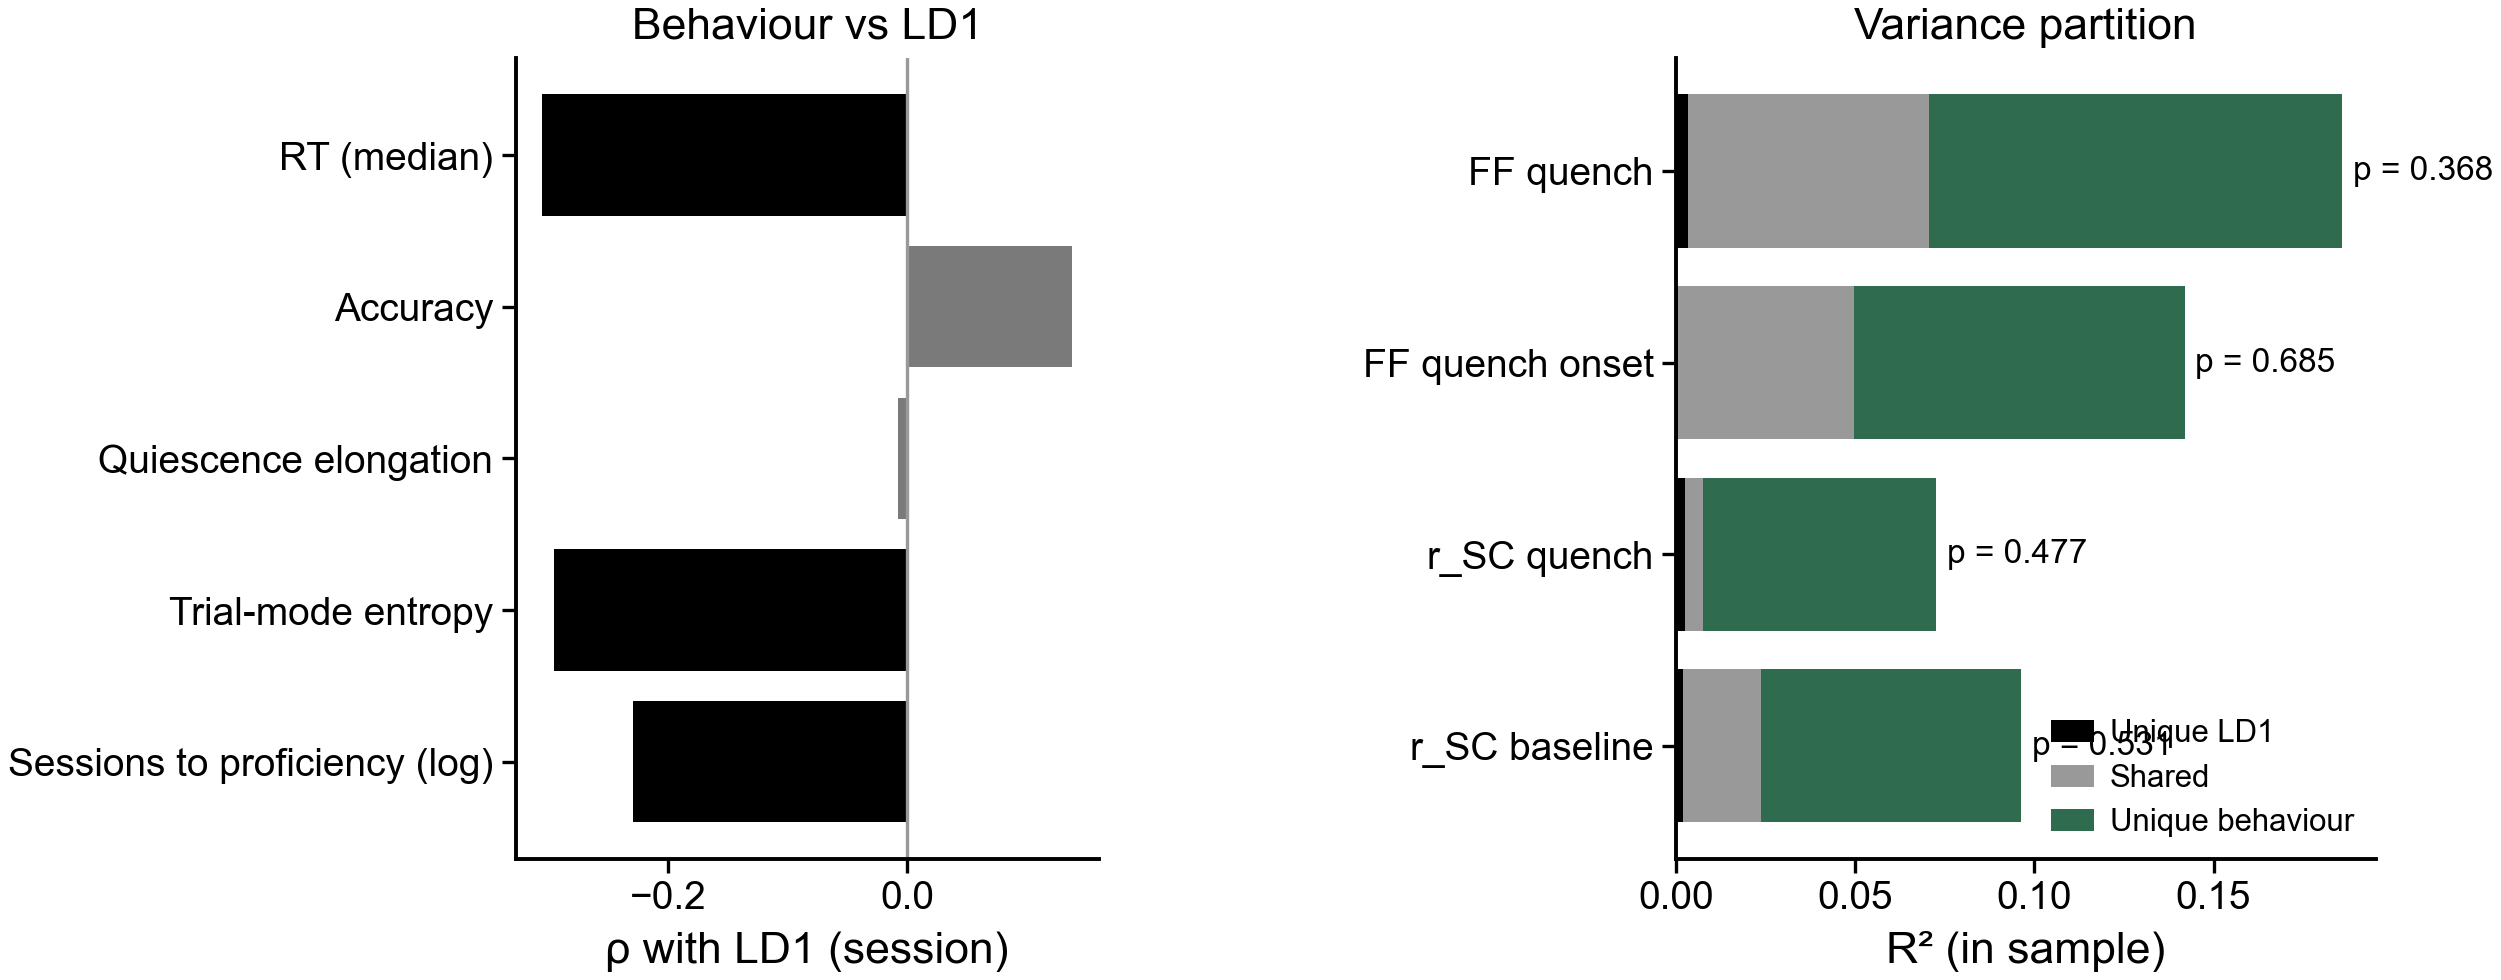

not saved (ps.SAVE_FIGURES is False): figures/neural_behaviour_models_11-10-2026.png, figures/neural_behaviour_models_11-10-2026.svg   -- ps.saving(True) to write, or pass save=True


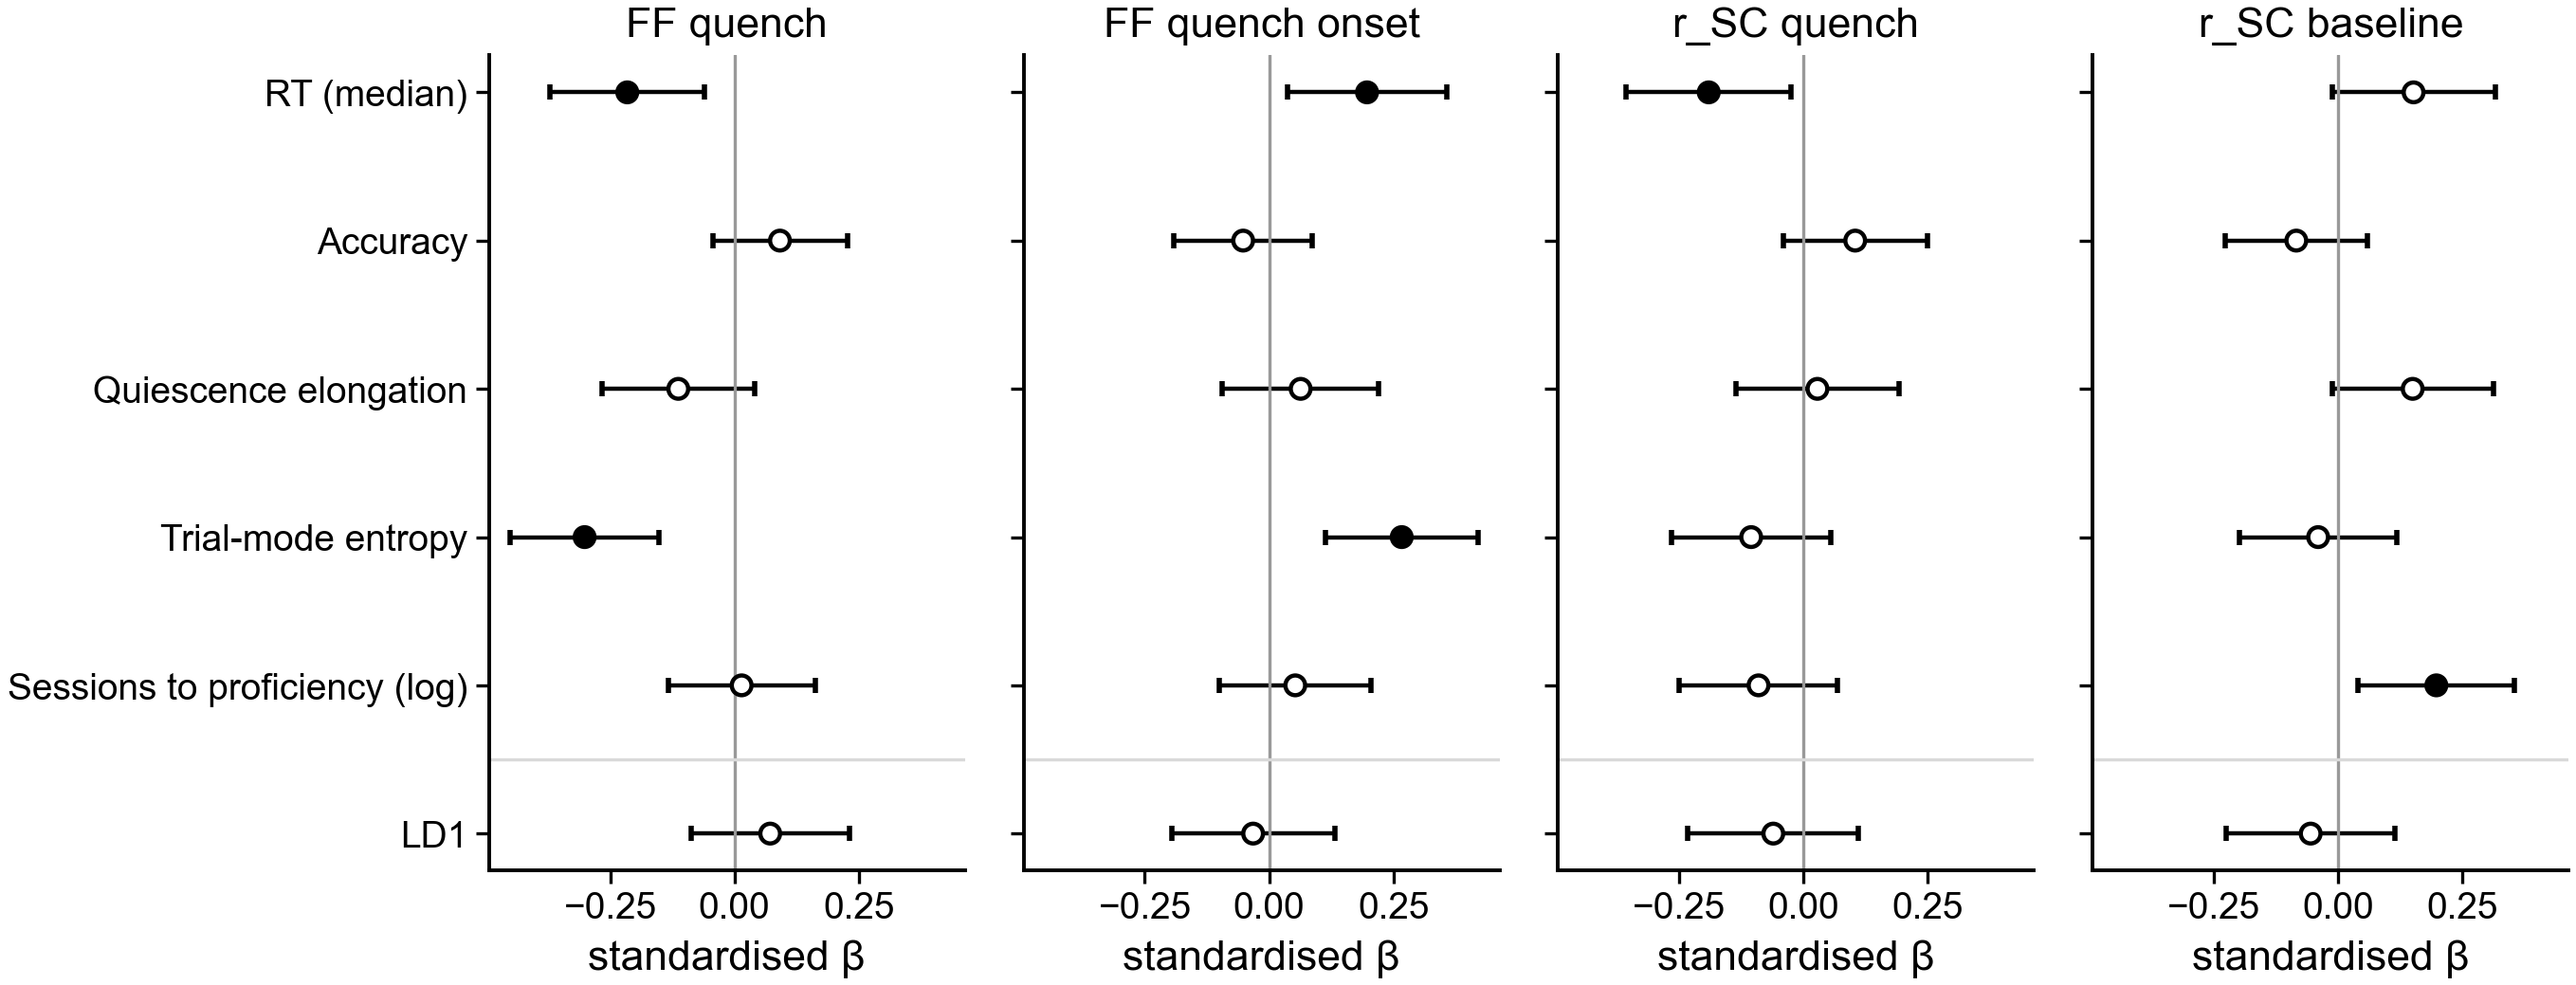

not saved (ps.SAVE_FIGURES is False): figures/neural_behaviour_coefficients_11-10-2026.png, figures/neural_behaviour_coefficients_11-10-2026.svg   -- ps.saving(True) to write, or pass save=True


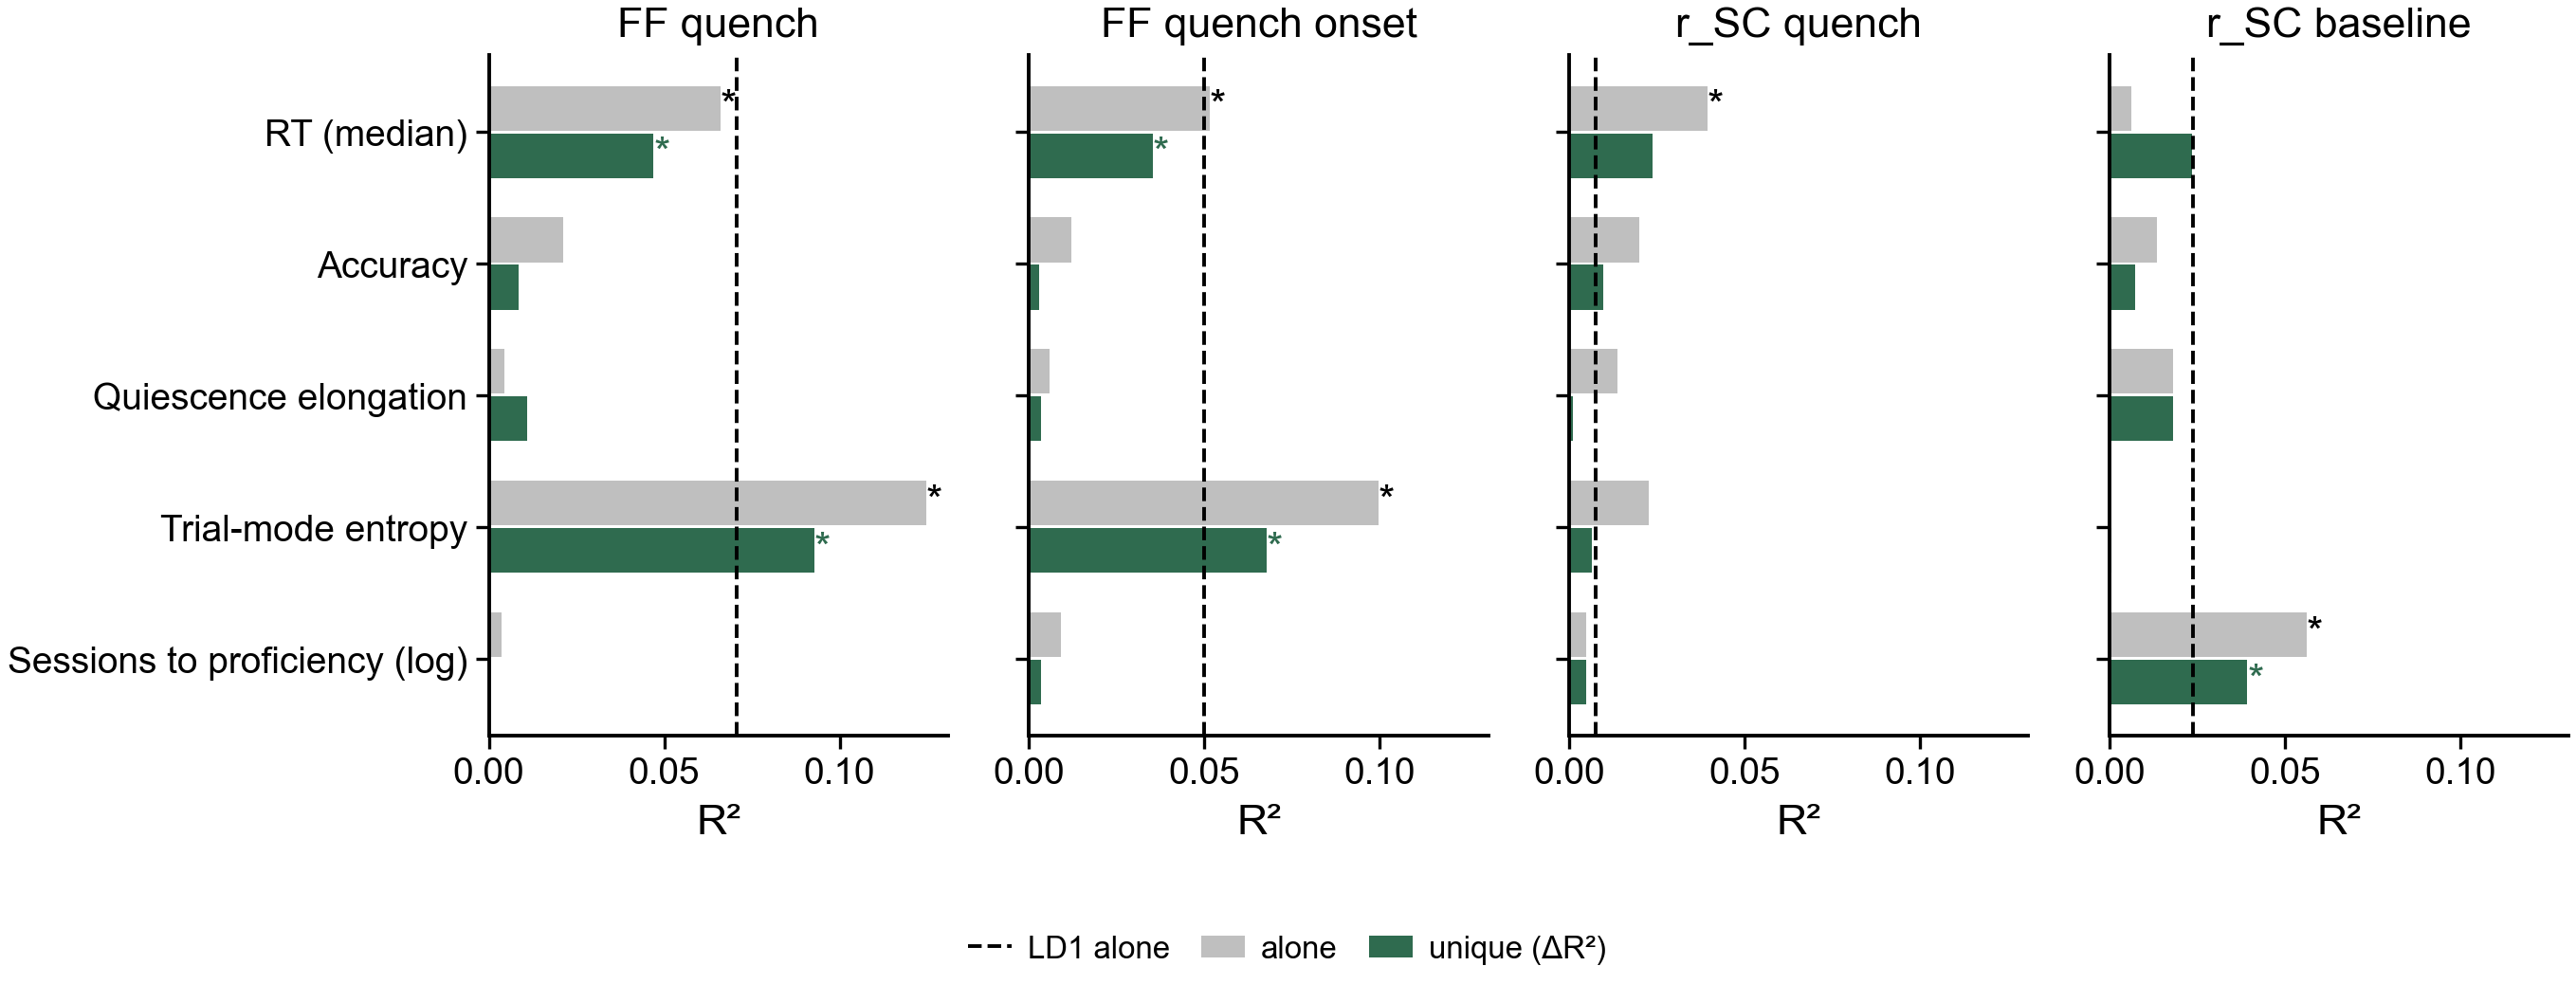

not saved (ps.SAVE_FIGURES is False): figures/neural_behaviour_r2_11-10-2026.png, figures/neural_behaviour_r2_11-10-2026.svg   -- ps.saving(True) to write, or pass save=True


[]

In [11]:
NICE = {'rt_median': 'RT (median)', 'rt_iqr': 'RT variability', 'performance': 'Accuracy', 'easy_error': 'Lapse rate',
        'choice_bias': 'Choice bias', 'elongation': 'Quiescence elongation', 'H_modes': 'Trial-mode entropy',
        'age_days': 'Age', 'learning_speed': 'Sessions to proficiency (log)', 'lda_1': 'LD1'}
fig = plt.figure(figsize=(6.0, 2.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.2], wspace=0.9)
ax = fig.add_subplot(gs[0])
s = SCREEN['rho_session'].reindex(PRED)
ax.barh(range(len(PRED)), s, color=[ps.NEUTRAL if p >= 0.05 else 'k' for p in SCREEN['p_session'].reindex(PRED)])
ax.set_yticks(range(len(PRED))); ax.set_yticklabels([NICE[c] for c in PRED]); ax.invert_yaxis()
ax.axvline(0, color='0.6', lw=0.6); ax.set_xlabel('ρ with LD1 (session)'); ax.set_title('Behaviour vs LD1', fontsize=plt.rcParams['font.size'])

ax = fig.add_subplot(gs[1])
outs = list(PART.index)
parts = [('unique_LD1', 'Unique LD1', 'k'), ('shared', 'Shared', '0.6'), ('unique_B', 'Unique behaviour', '#2f6b4f')]
left = np.zeros(len(outs))
for col, lab_, c in parts:
    v = PART[col].clip(lower=0).to_numpy()
    ax.barh(range(len(outs)), v, left=left, color=c, label=lab_)
    left += v
for i, o in enumerate(outs):
    ax.text(left[i] + 0.003, i, f"p = {PART.loc[o, 'p_unique_LD1']:.3f}", va='center', fontsize=plt.rcParams['font.size'] * 0.75)
ax.set_yticks(range(len(outs))); ax.set_yticklabels(outs); ax.invert_yaxis()
ax.set_xlabel('R² (in sample)'); ax.legend(frameon=False, fontsize=plt.rcParams['legend.fontsize'] * 0.8, loc='lower right')
ax.set_title('Variance partition', fontsize=plt.rcParams['font.size'])

plt.show()
ps.savefig(fig, 'neural_behaviour_models', svg=True)

# the full-model coefficients, one panel per outcome, on one x scale (standardised beta, 95% CI mouse-clustered;
# filled = p < 0.05)
fig, axes = plt.subplots(1, len(Y.columns), figsize=(7.0, 2.8), sharey=True, sharex=True)
for ax, y in zip(axes, Y.columns):
    c = COEF[COEF['outcome'] == y].set_index('predictor').reindex(PRED + ['lda_1'])
    yy = np.arange(len(c))
    ax.errorbar(c['beta'], yy, xerr=[c['beta'] - c['lo'], c['hi'] - c['beta']], fmt='none', lw=0.8, color='k')
    ax.scatter(c['beta'], yy, s=14, zorder=3, edgecolors='k', linewidths=0.8,
               c=['k' if p < 0.05 else 'white' for p in c['p']])
    ax.axvline(0, color='0.6', lw=0.6)
    ax.axhline(len(PRED) - 0.5, color='0.85', lw=0.6)          # LD1 below the line
    ax.set_title(y, fontsize=plt.rcParams['font.size'])
    ax.set_xlabel('standardised β')
axes[0].set_yticks(np.arange(len(PRED) + 1)); axes[0].set_yticklabels([NICE[k] for k in PRED + ['lda_1']]); axes[0].invert_yaxis()
fig.tight_layout()
plt.show()
ps.savefig(fig, 'neural_behaviour_coefficients', svg=True)

# one predictor at a time (behaviour only): R² alone (light) and unique ΔR² in the five-behaviour model (dark);
# * = q < 0.05 within outcome. LD1's R² alone is the dashed line, for reference
fig, axes = plt.subplots(1, len(Y.columns), figsize=(7.0, 2.6), sharey=True, sharex=True)
for ax, y in zip(axes, Y.columns):
    o = ONE[ONE['outcome'] == y].set_index('predictor').reindex(ALL)
    yy = np.arange(len(o))
    ax.barh(yy - 0.18, o['r2_alone'], height=0.34, color='0.75', label='alone')
    ax.barh(yy + 0.18, o['dr2_unique'].clip(lower=0), height=0.34, color='#2f6b4f', label='unique (ΔR²)')
    for k, (a, qa, u, qu) in enumerate(zip(o['r2_alone'], o['q_alone'], o['dr2_unique'], o['q_unique'])):
        if qa < 0.05: ax.text(a, k - 0.18, '*', va='center', fontsize=plt.rcParams['font.size'])
        if qu < 0.05: ax.text(max(u, 0), k + 0.18, '*', va='center', fontsize=plt.rcParams['font.size'], color='#2f6b4f')
    ax.axvline(fit_ols(D.dropna(subset=[y]), ['lda_1'], y).rsquared, color='k', ls='--', lw=0.7, label='LD1 alone')
    ax.set_title(y, fontsize=plt.rcParams['font.size']); ax.set_xlabel('R²')
axes[0].set_yticks(np.arange(len(ALL))); axes[0].set_yticklabels([NICE[k] for k in ALL]); axes[0].invert_yaxis()
fig.legend(*axes[-1].get_legend_handles_labels(), frameon=False, fontsize=plt.rcParams['legend.fontsize'] * 0.85,
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()
ps.savefig(fig, 'neural_behaviour_r2', svg=True)

In [12]:
OUT = ROOT / 'lda1_tables'
stamp = pd.Timestamp.today().strftime('%d-%m-%Y')
for name, df in [('screen', SCREEN), ('univariate', UNI), ('partition', PART), ('coefficients', COEF), ('one_at_a_time', ONE)]:
    df.to_csv(OUT / f'behaviour_models_{name}_{stamp}.csv')
print('wrote behaviour_models_{screen,univariate,partition,coefficients,one_at_a_time}_' + stamp + '.csv in', OUT.name)

wrote behaviour_models_{screen,univariate,partition,coefficients,one_at_a_time}_11-10-2026.csv in lda1_tables
